# Lab 3 · Graph search to ground truth

The generating equation is $u_{tt}=0.85\Delta u+0.72u_{xy}$. Its structure is used only for the reference and stopping checks, and is excluded from the initial pool. Coefficients are fitted from data. Helpers live in `lab3/quality_search.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lab3" / "experiment.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from WavePropagation or its lab3 folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from lab3.quality_search import (
    plot_generation_history,
    plot_search_progress,
    prepare_benchmark,
    search_until_quality,
)
from lab3.report import symbolic_equations

SEED = 55
MAX_UNIQUE = None  # Optional cap on distinct evaluations, including the initial 12.
torch.set_num_threads(1)

## Reference score

Fit the known structure on the same training rows and score it on the same validation rows as every candidate:

$$J(G)=\mathrm{NMSE}_{\mathrm{val,weak}}(G)+0.0015\,C(G)+0.035[1-R(G)].$$

Here $C$ is graph complexity and $R$ is mean coefficient retention under mild shuffling. An eligible candidate has full rank and passes the clean coefficient-support check.

In [2]:
with threadpool_limits(limits=1):
    wave, scorer, known = prepare_benchmark()

print(f"Known-equation validation score: {known.score():.12g}")

Known-equation validation score: 0.0120135517841


## Generate until the ground-truth structure is recovered

Use the original 12 initial graphs and model update schedule. Stop when a sampled graph has exactly the canonical ground-truth structure, passes the rank/support checks, and has $J(G)\leq J(G_{\mathrm{known}})+10^{-12}$. Preserve the successful proposal's original rule sequence returned by the sampler.

In [3]:
with threadpool_limits(limits=1):
    run = search_until_quality(
        wave, scorer, known.score(), seed=SEED, max_unique=MAX_UNIQUE, require_exact=True,
    )

status = "Ground-truth structure recovered" if run["reached"] else "Evaluation cap reached"
print(f"{status} after {len(run['curve']):,} distinct graph evaluations.")

Ground-truth structure recovered after 232 distinct graph evaluations.


## Search progress

One curve shows the best eligible validation score so far. Zero new evaluations corresponds to the end of the shared initial pool.

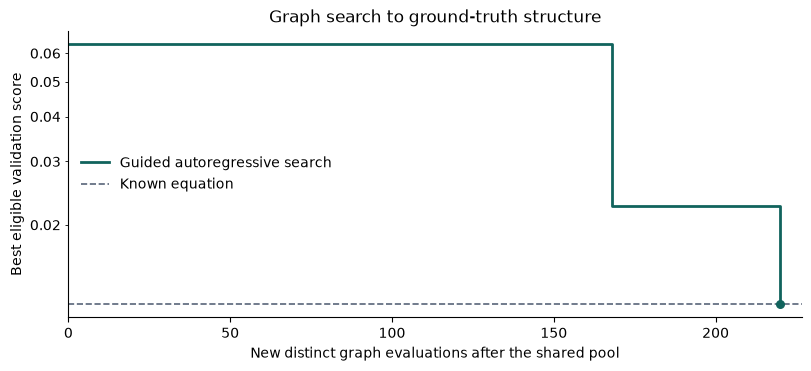

In [4]:
fig = plot_search_progress(run, known.score())
plt.show()

## Recovered equation

In [5]:
display(Markdown(symbolic_equations([("Recovered structure, refitted coefficients", run["final"])])))
print(f"Validation score: {run['final']['score']:.12g}")
print(f"Held-out weak NMSE: {run['heldout_nmse']:.12g}")

**Recovered structure, refitted coefficients**

$$u_{tt} = 0.7452756399978079\,\partial_{xy} u + 0.8612363214870679\,\Delta u$$

Validation score: 0.0120135517841
Held-out weak NMSE: 1.51117772852e-05


## Generation history of the successful candidate

Five snapshots from the **same sampled rule sequence**, from the masked start to the completed derivation. Gray `?` nodes are unresolved slots; green nodes are operators and blue nodes are observed fields. Node positions stay fixed across snapshots. The root $\Sigma$ assembles the branches; coefficients are fitted after generation.

These are the actual sampled rules before canonicalization, rather than a new encoding of the final equation.

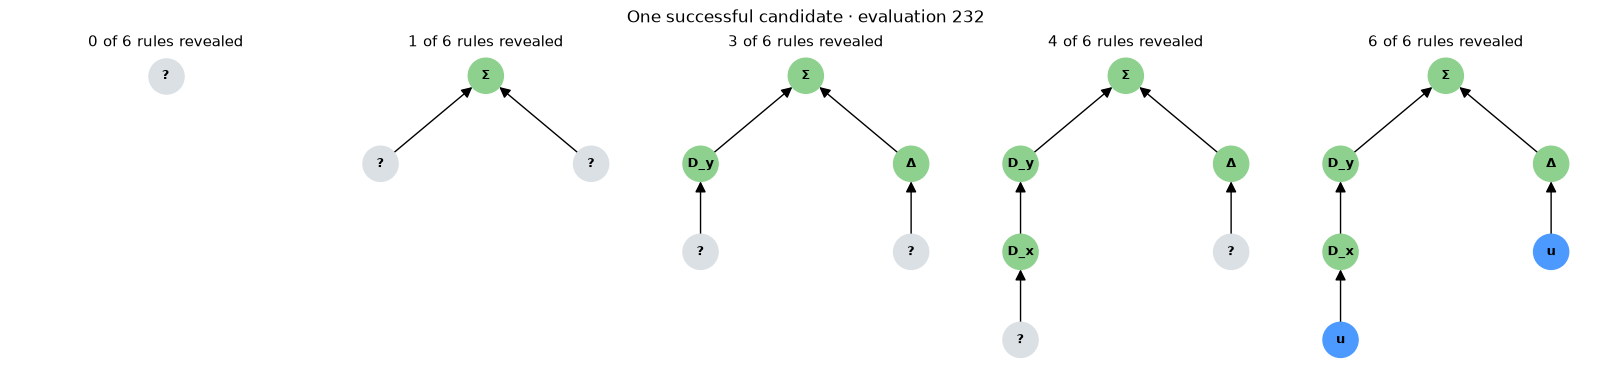

In [6]:
fig = plot_generation_history(run, count=5)
plt.show()